# 105_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Beijing (12 estaciones, promedio) horario · PM2.5 (log) · rezago 1 cruzado · $M = 10$

El `300_04` sobre la corrida 105 (construcción nueva: base 10/3, cruzadas con un rezago, una cadena, `atau = 2`, `psbp_train.m` vigente): cuatro predictores puntuales y tres intervalos (docs §03_05) y comportamientos predictivos (§03_06). Datos reales: objetivo = curva suavizada, §7 sin contraste con un generador y §12.4 contra el calendario y los días de episodio.


## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    INTERVALOS as INTERVALOS_TODOS, tabla_intervalos, filtrar_ventana,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import comportamientos_barrido, catalogo_barrido
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo,
)
from model_psbp_fd.graphics.viz_evaluacion_barrido import (
    plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M,
)
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

import json

from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.fit.resumenes_predictiva import distancia_a_muestra_mas_cercana

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 105_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "beijing_105", 1   # ventana 1: 2013-03-01 .. 2017-02-28, 70/30 (105_01 §1.1)
M_FPCA_LIST = (10,)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None
# Episodios (§3.2, §12.4): un día es de contaminación severa si su promedio de 24 h de PM2.5 es
# >= UMBRAL_SEVERO_PM25 µg/m³ (AQI chino 'contaminación fuerte'); X_obs = log(1 + PM2.5) (105_01 §2.1).
UMBRAL_SEVERO_PM25 = 150.0   # µg/m³ (75 lo supera el 40 % de los días: no separa)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 105_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat (500), como las 30x.
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria; G = 24)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr (docs §03_05_05)
K_MAX_HDR      = 3                    # tramos por (t, tau) de la HDR
N_DETALLE      = 10                   # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE     = None                 # None = criterio automático del escenario; un entero lo fija a mano
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
M_DETALLE      = (10,)                # figuras por origen sólo en estos M (un solo punto)
N_EJEMPLOS     = 4

# §7: dispersión entre cadenas del PIP que se avisa (con 1 cadena no hay dispersión).
SD_PIP_MAX = 0.15

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : real_beijing_105_v01
barrido en M    : [10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_obs, X_suav = DIS["grilla"], DIS["X_obs"], DIS["X_suav"]      # sin X_true: datos reales

  M  comp  cadenas  covariables  seed_base
 10    10        1           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)
M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1461, 24)

OK 1 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1461 T0=1022 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)     # los M efectivamente disponibles

OK M=10: 10 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU,
                 intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)

# La HDR fusiona tramos cuando una (t, tau) da más de K_MAX_HDR: no debe pasar del 1 %.
for M in M_OK:
    print(f"M={M}: HDR con fusión de tramos en {EST[M]['hdr_fusiones']} (t, tau) "
          f"= {EST[M]['hdr_frac_fusiones']:.3%}")
assert max(EST[M]["hdr_frac_fusiones"] for M in M_OK) <= 0.01, "subir K_MAX_HDR y reportarlo"

origenes evaluados: 1460  (train 1021 · test 439)
SC_draws de TODO el barrido: 117 MB en float32


M=10: HDR puntual (k_max=3, recorte None): (t, g) con 1/2/3... tramos 99.91% / 0.09% / 0.00% · fusiones en 0.00% de los (t, g)


M=10: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 117 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.000000   <- distancia del objetivo a su propia proyeccion en M
M=10: HDR con fusión de tramos en 0 (t, tau) = 0.000%


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=10] banda funcional -> banda_funcional_psbp.npz  (1.2 MB, (1460, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (117 MB, (2000, 1460, 10))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

`N_DETALLE` orígenes consecutivos de prueba para el análisis por origen (§6, §11, §12.2–§12.5; en el `_05`, §9–§10). Criterio automático sobre lo observado, nunca sobre lo predicho: **episodios severos**: la ventana de prueba con más días cuyo promedio observado de 24 h de PM2.5 supera `UMBRAL_SEVERO_PM25` µg/m³. Se guarda en `112_ventana_detalle.json`; con 10 orígenes las cifras son cuentas.


In [7]:
# 105 (Beijing): calendario y episodios de los días predichos. Episodio = promedio de 24 h de PM2.5 observado
# >= UMBRAL_SEVERO_PM25. Criterio automático: la ventana de N_DETALLE días de prueba con más días de episodio;
# en empate, la primera. La ventana cae en las acumulaciones y cortes de invierno, donde se espera la bimodalidad.
DIAS = pd.to_datetime(pd.read_csv(EST[M_OK[0]]["paths"]["raw"] / "dias.csv")["dia"])
assert len(DIAS) == T, f"dias.csv trae {len(DIAS)} días y T = {T}"
MEDIDA  = np.expm1(X_obs).mean(axis=1)                                # (T,) promedio diario de PM2.5, µg/m³
EVENTO  = MEDIDA >= UMBRAL_SEVERO_PM25                                 # (T,) día de episodio severo
NOMBRE_EVENTO, NOMBRE_MEDIDA = "episodio", "pm25_media"            # columnas en 65_* y 112_*
DESCR_EVENTO = f"día de episodio severo (promedio de 24 h de PM2.5 >= {UMBRAL_SEVERO_PM25:g} µg/m³)"
DIA_SEM   = DIAS.dt.day_name().str[:3].to_numpy()                       # (T,) Mon .. Sun
MES       = DIAS.dt.month.to_numpy()                                    # (T,) 1 .. 12
EVENTO_OR = EVENTO[t_orig - 1].astype(int)                              # el día PREDICHO de cada origen
i_test = np.flatnonzero(~es_train)
cand   = i_test[: len(i_test) - N_DETALLE + 1]
puntaje = np.array([EVENTO_OR[i:i + N_DETALLE].sum() for i in cand])
j = int(np.argmax(puntaje))                                             # empate: la primera
T0_DETALLE_AUTO = int(t_orig[cand[j]])
CRITERIO_DET    = f"{DESCR_EVENTO} entre los días predichos de la ventana, suma"
VALOR_DET       = float(puntaje[j])
VERDAD_DET = {"fecha": DIAS.dt.strftime("%Y-%m-%d").to_numpy()[t_orig - 1],
              "dia_semana": DIA_SEM[t_orig - 1], "mes": MES[t_orig - 1],
              NOMBRE_MEDIDA: MEDIDA[t_orig - 1],
              NOMBRE_EVENTO: EVENTO_OR, f"ayer_{NOMBRE_EVENTO}": EVENTO[t_orig - 2].astype(int)}
print(f"{DESCR_EVENTO}: {int(EVENTO.sum())} de {T} días (train {int(EVENTO[:T0].sum())}, test {int(EVENTO[T0:].sum())})")


día de episodio severo (promedio de 24 h de PM2.5 >= 150 µg/m³): 177 de 1461 días (train 118, test 59)


In [8]:
if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")

Ventana de detalle: t = 1400..1409   ·   día de episodio severo (promedio de 24 h de PM2.5 >= 150 µg/m³) entre los días predichos de la ventana, suma: 9


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.7s  t=16 [train] mise=0.7296


  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] mise=0.5025


  142/1431 ( 9.9%) t=0.0s eta=0.2s  t=157 [train] mise=0.4041


  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] mise=0.7341


...

  1349/1431 (94.3%) t=0.2s eta=0.0s  t=1364 [test] mise=0.7744


  1420/1431 (99.2%) t=0.2s eta=0.0s  t=1435 [test] mise=0.8597


  1431/1431 (100.0%) t=0.2s eta=0.0s  t=1446 [test] mise=0.627


[ventana_movil_funcional[w=30]] listo: 1431 pasos en 0.2s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 1 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


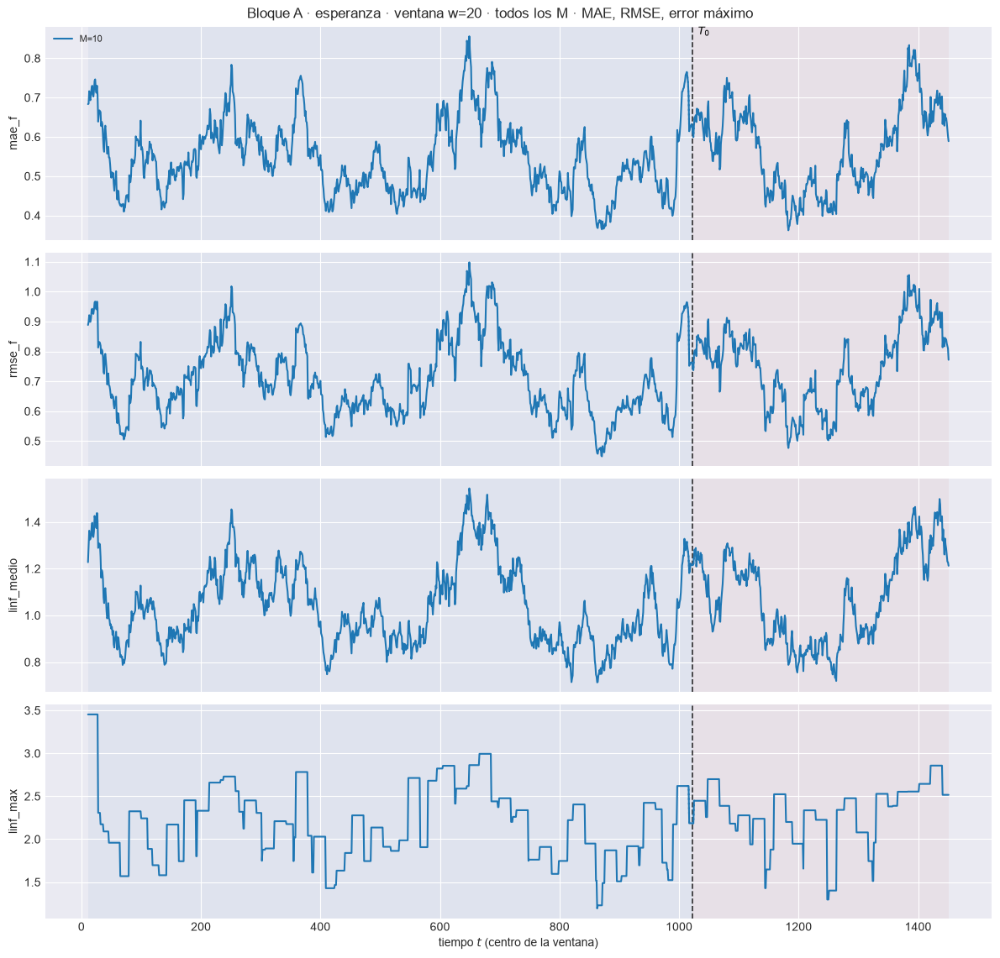

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.531  w=30 test=0.5593


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.6884  w=30 test=0.7479


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=0.9897  w=30 test=1.038


  4/4 (100.0%) t=0.0s eta=0.0s  linf_max: w=30 train=2.325  w=30 test=2.477


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_barrido_M\85_bloqueA_w30.png


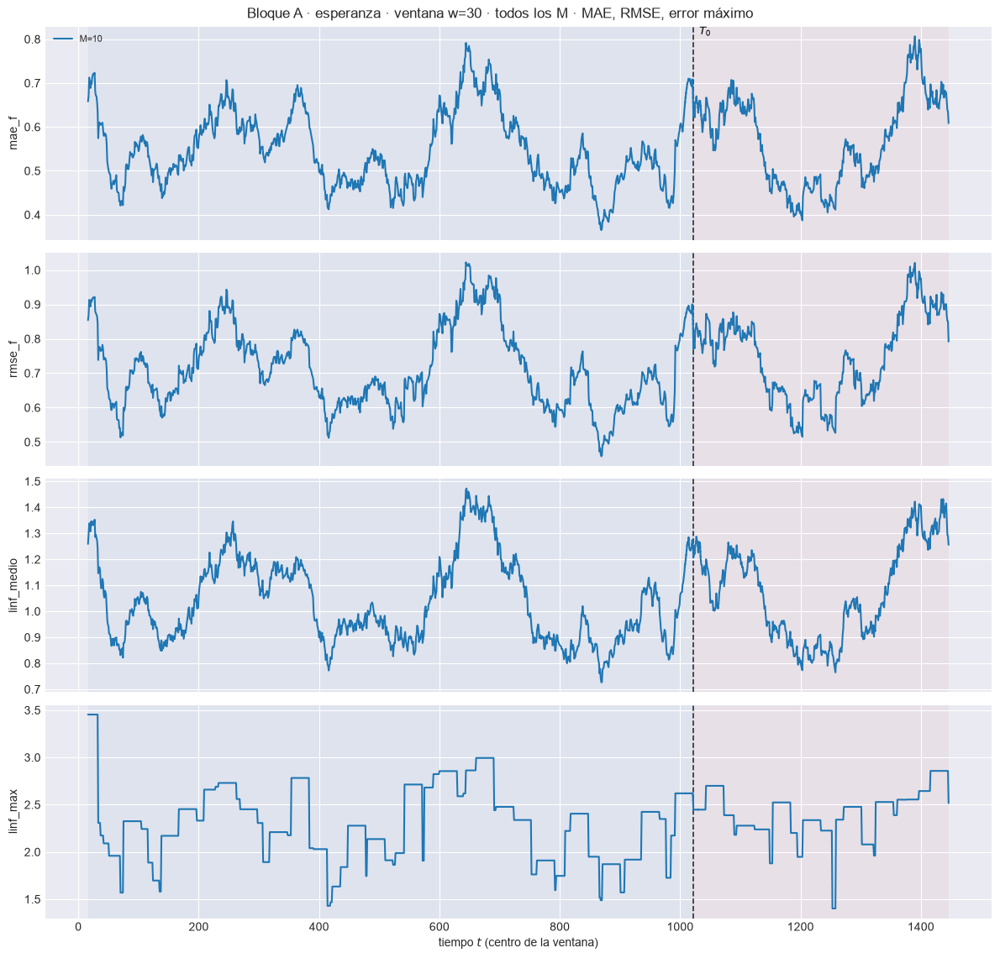

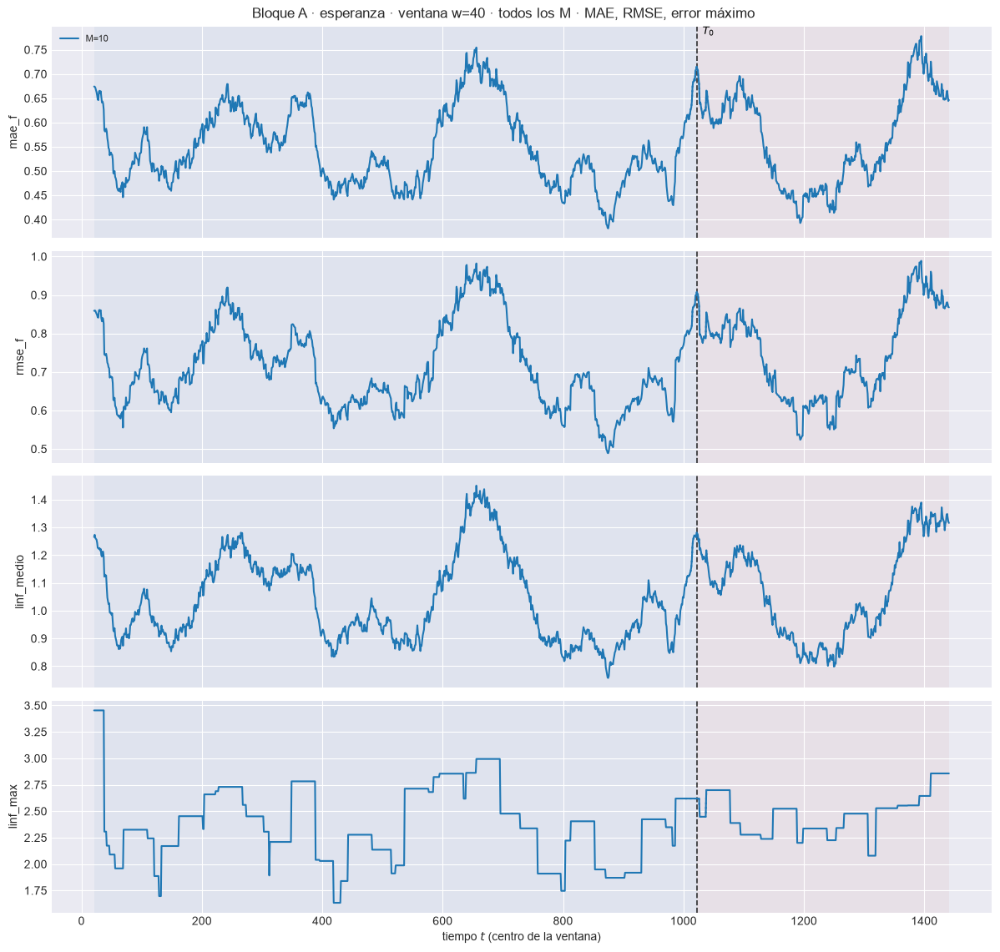

In [9]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

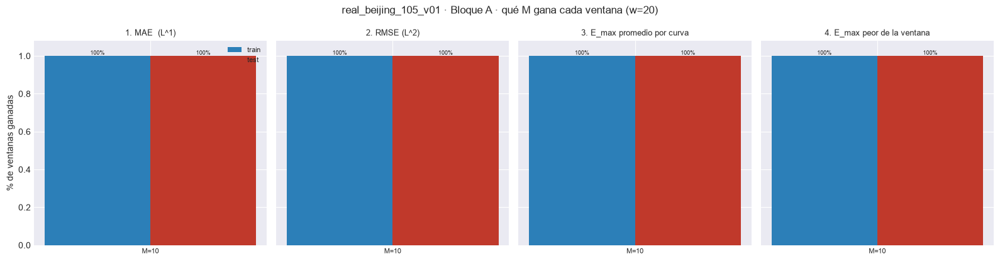

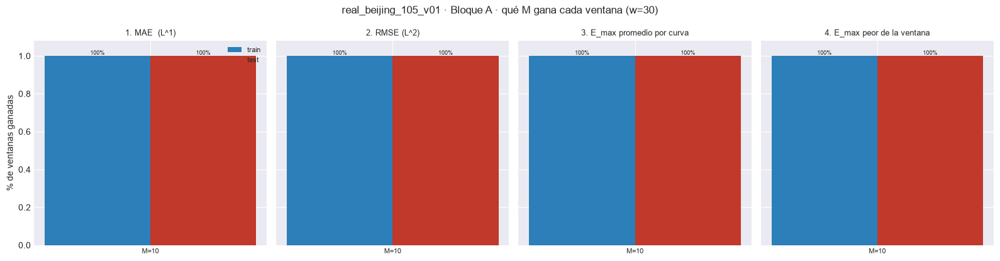

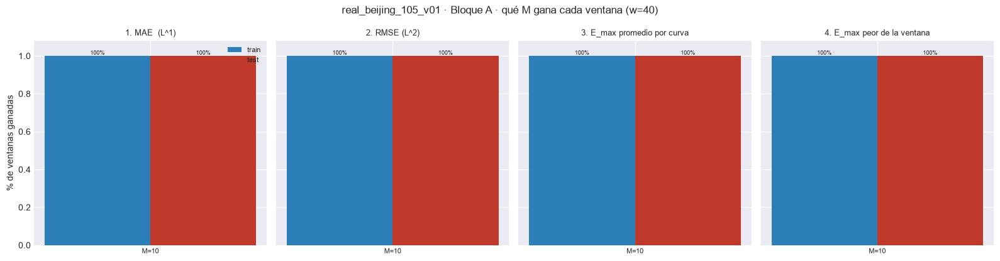

In [10]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [11]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,10
predictor,
esperanza,14.4%
mediana,54.6%
medoide,7.1%
modal,23.9%


M,10
predictor,
esperanza,56.8%
mediana,40.7%
medoide,2.4%
modal,0.0%


M,10
predictor,
esperanza,32.4%
mediana,46.8%
medoide,1.7%
modal,19.0%


M,10
predictor,
esperanza,97.3%
mediana,0.0%
medoide,2.7%
modal,0.0%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

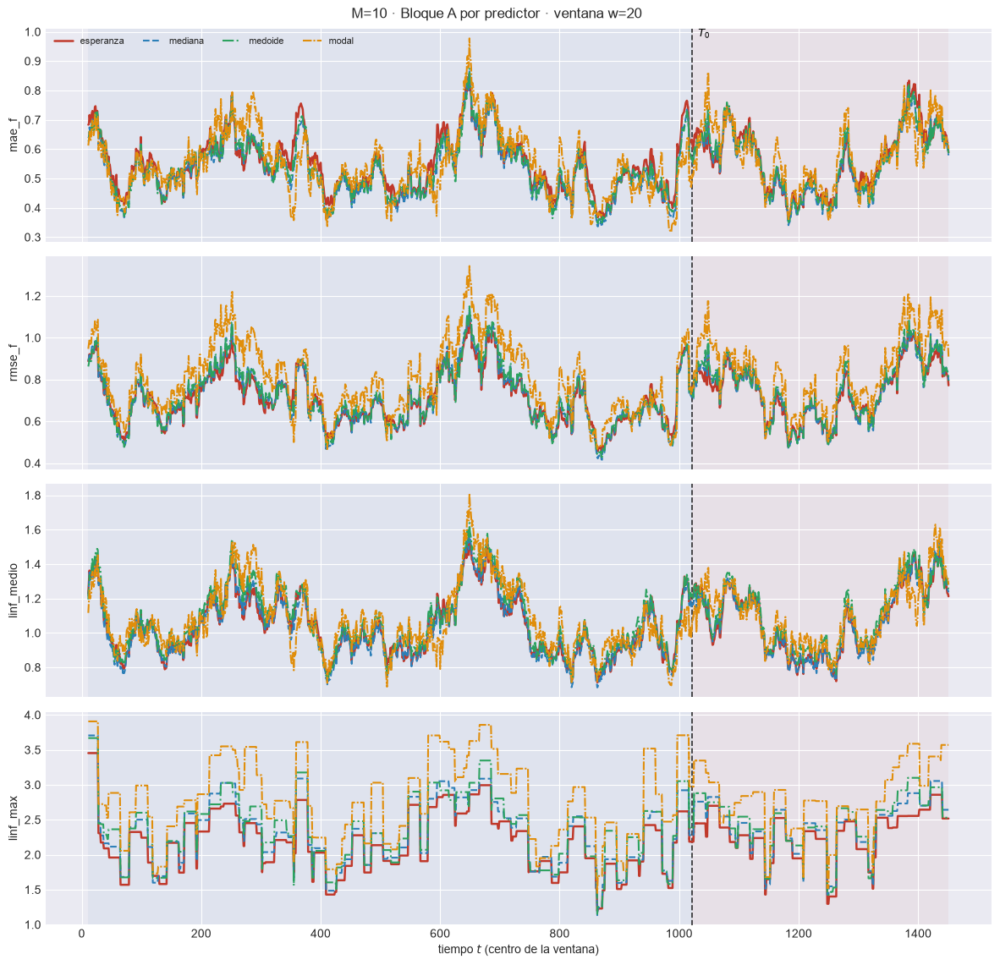

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.5228  w=30 test=0.5705


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.7086  w=30 test=0.7755


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.007  w=30 test=1.069


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.501  w=30 test=2.593


[plot_ventana_movil] listo: 4 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_m10\58_ventana_predictores_w30.png


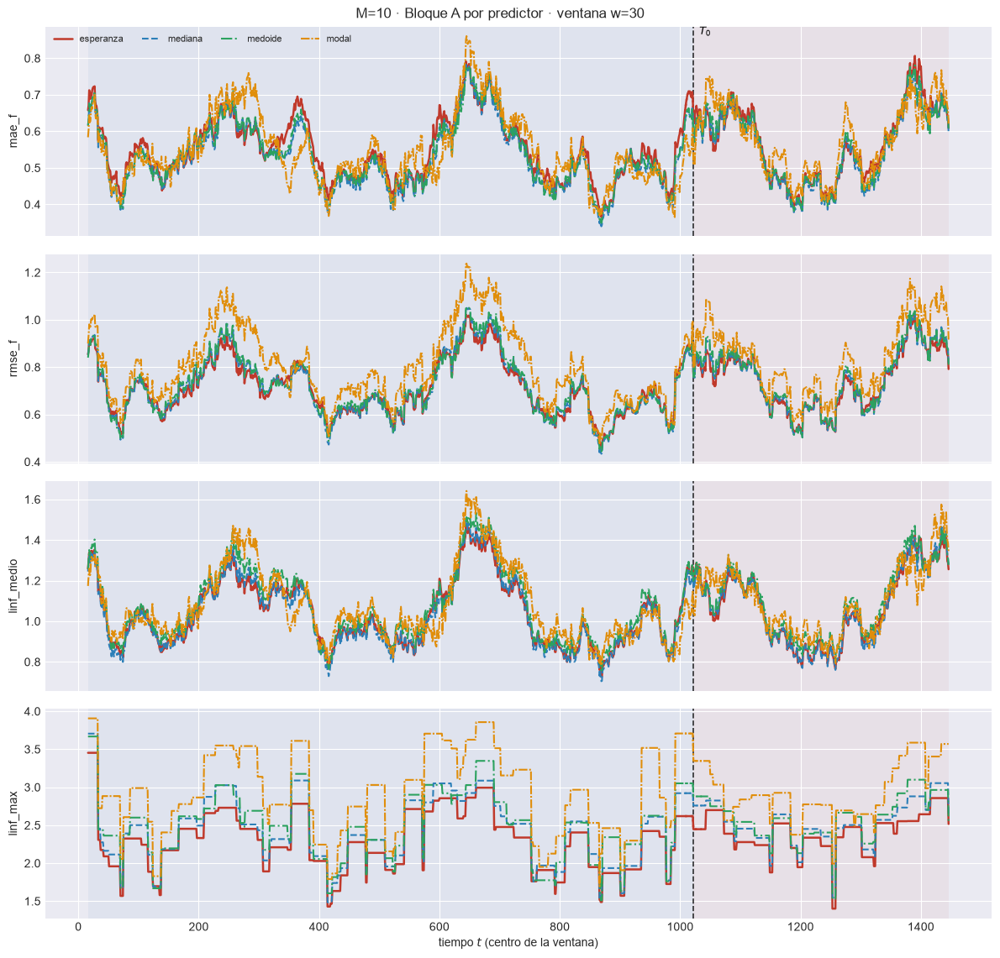

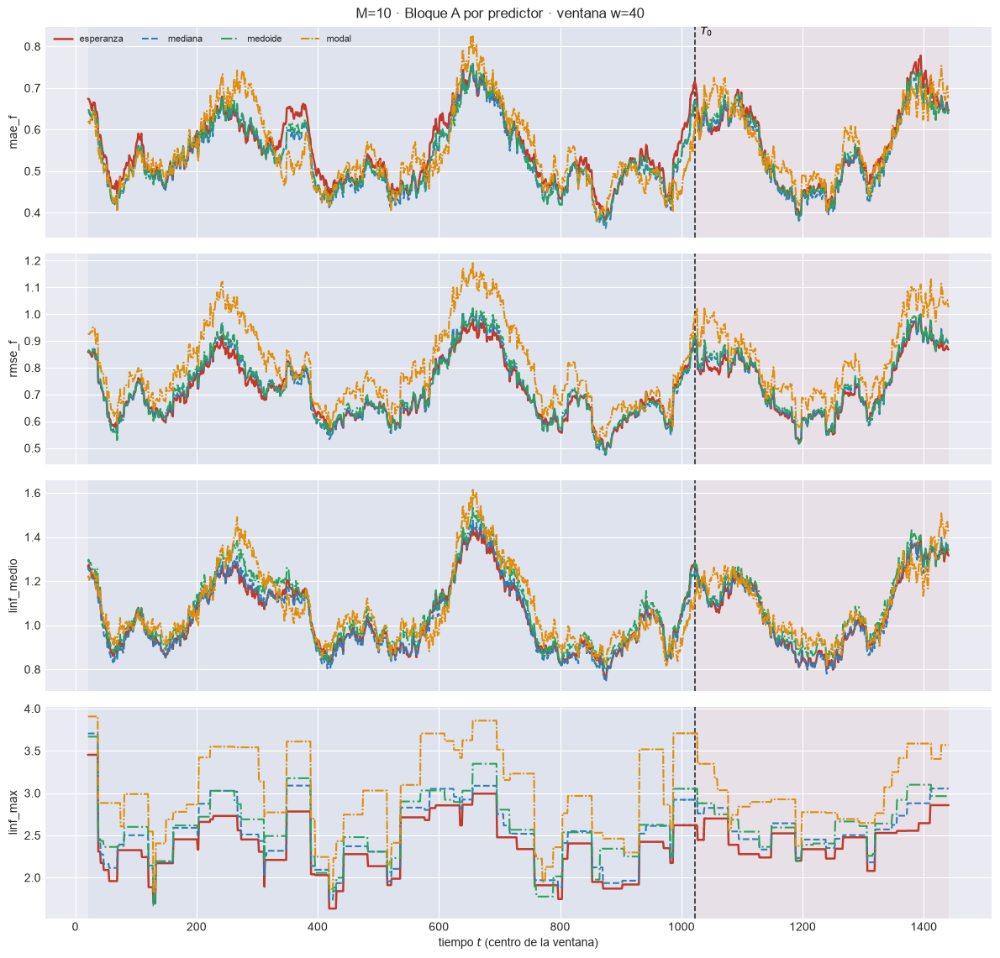

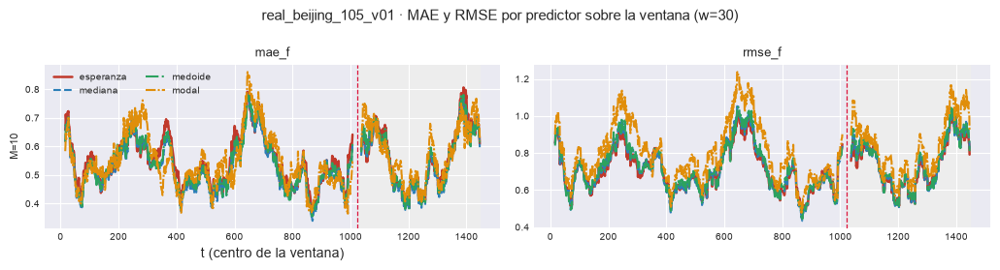

In [12]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        tp = filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas")
        tp.attrs["w"] = w
        plot_ventana_movil(
            tp, T0, METRICAS_A_COLS, columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

plot_ventana_grupos_por_M(
    {M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
    ["mae_f", "rmse_f"], "predictor", T0, ESTILOS_PREDICTORES,
    f"{EXPERIMENT_BASE} · MAE y RMSE por predictor sobre la ventana (w={W_REF})",
    PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

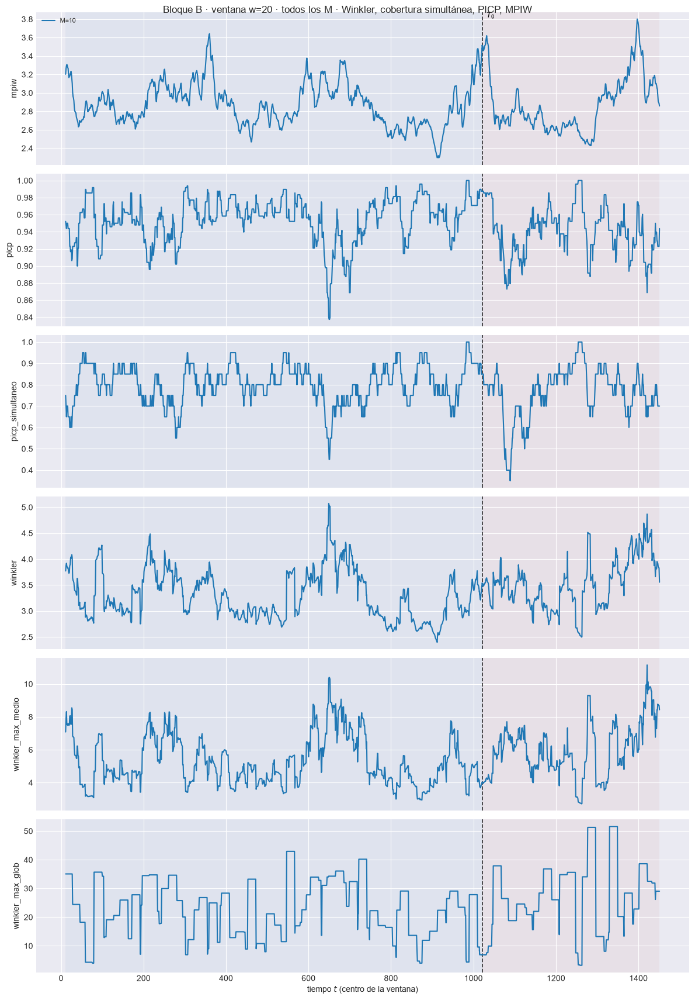

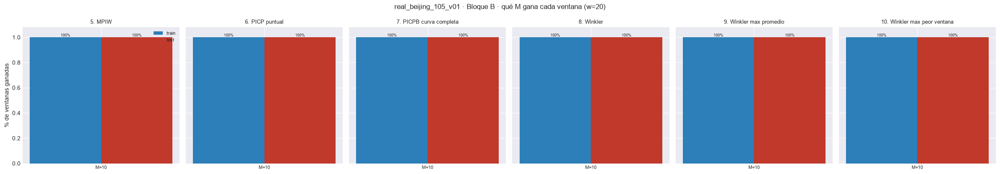

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.0s  mpiw: w=30 train=2.856  w=30 test=2.766


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9597  w=30 test=0.9389


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.8  w=30 test=0.7667


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=3.235  w=30 test=3.429


  5/6 (83.3%) t=0.0s eta=0.0s  winkler_max_medio: w=30 train=4.868  w=30 test=6.1


  6/6 (100.0%) t=0.0s eta=0.0s  winkler_max_glob: w=30 train=27.78  w=30 test=34.06


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_barrido_M\86_bloqueB_w30.png


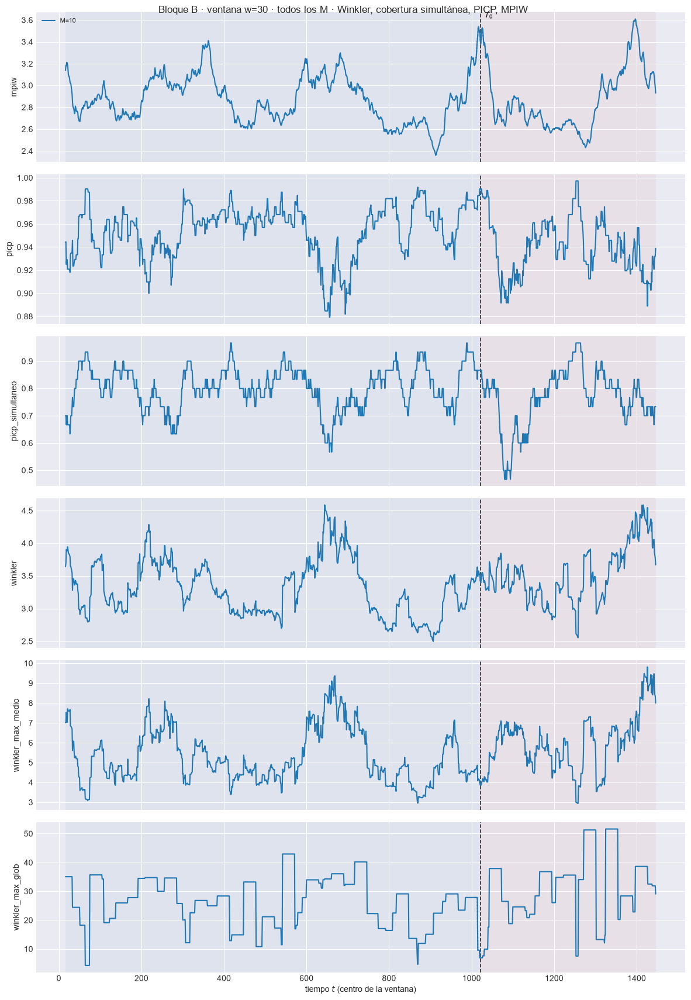

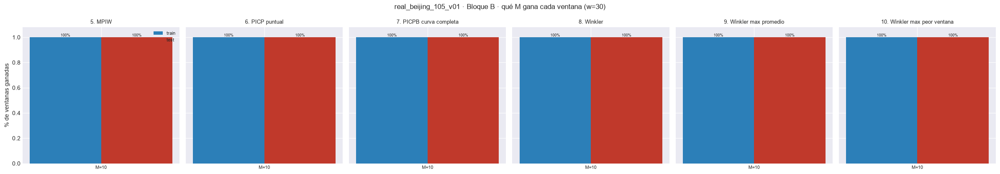

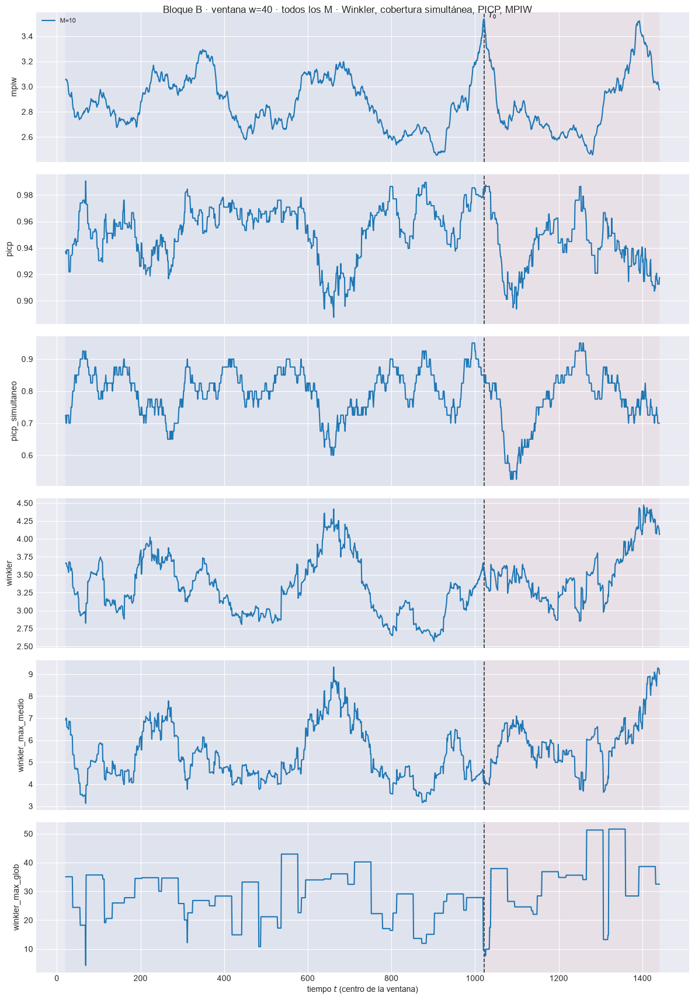

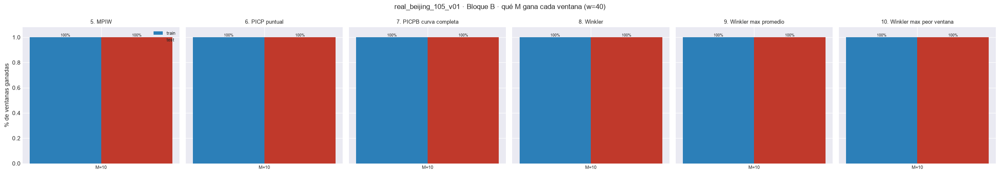

In [13]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

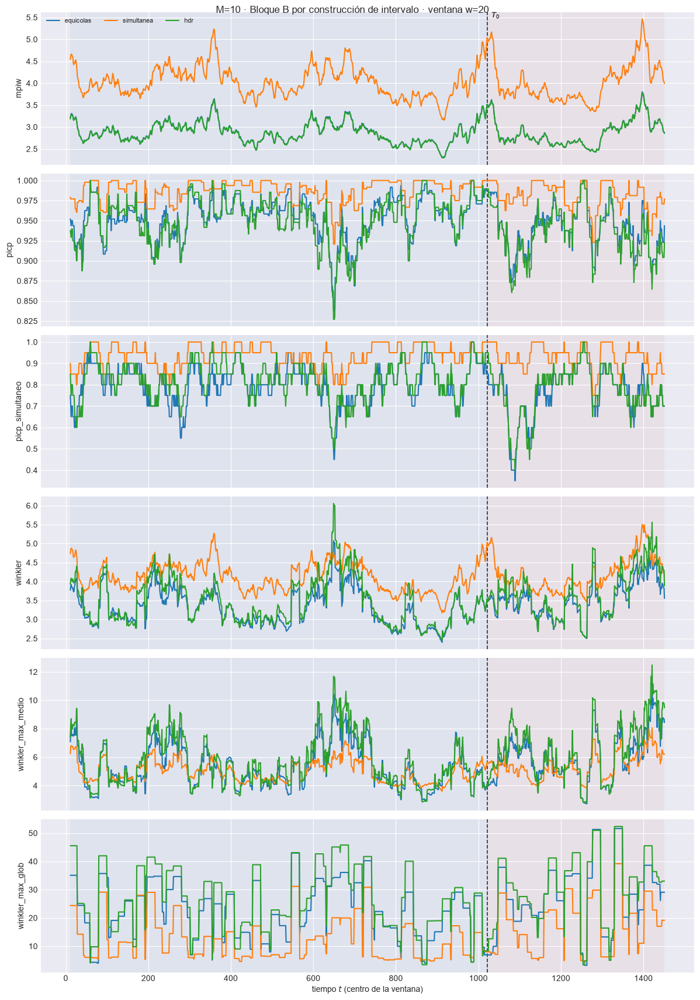

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.018  w=30 test=3.024


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9681  w=30 test=0.9528


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.8667  w=30 test=0.8333


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=3.633  w=30 test=3.818


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=4.99  w=30 test=5.834


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=24.36  w=30 test=29.82


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_m10\59_ventana_intervalos_w30.png


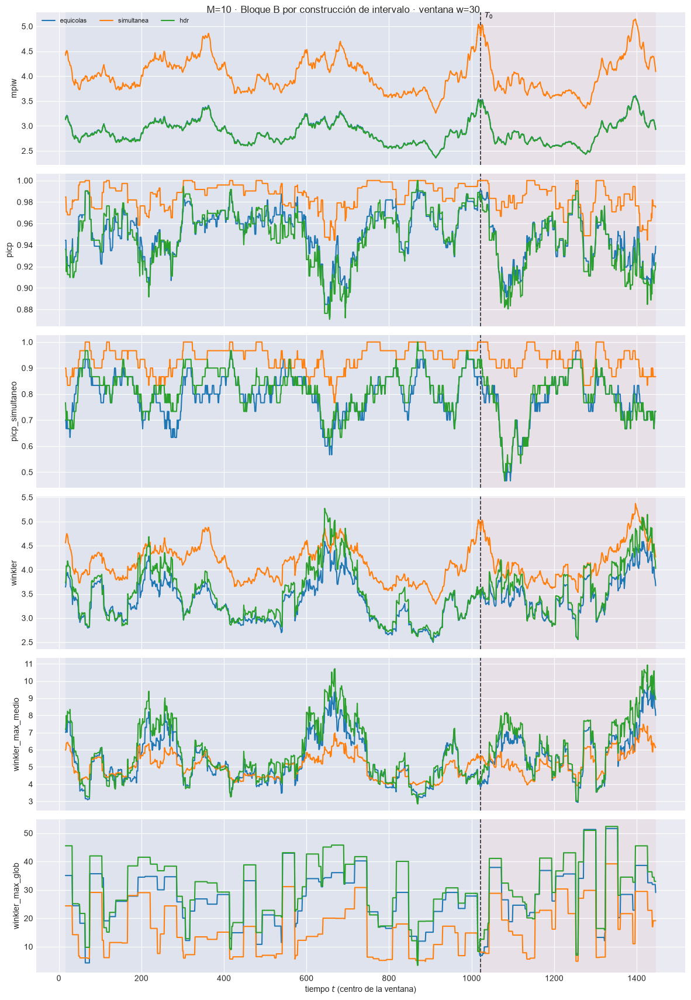

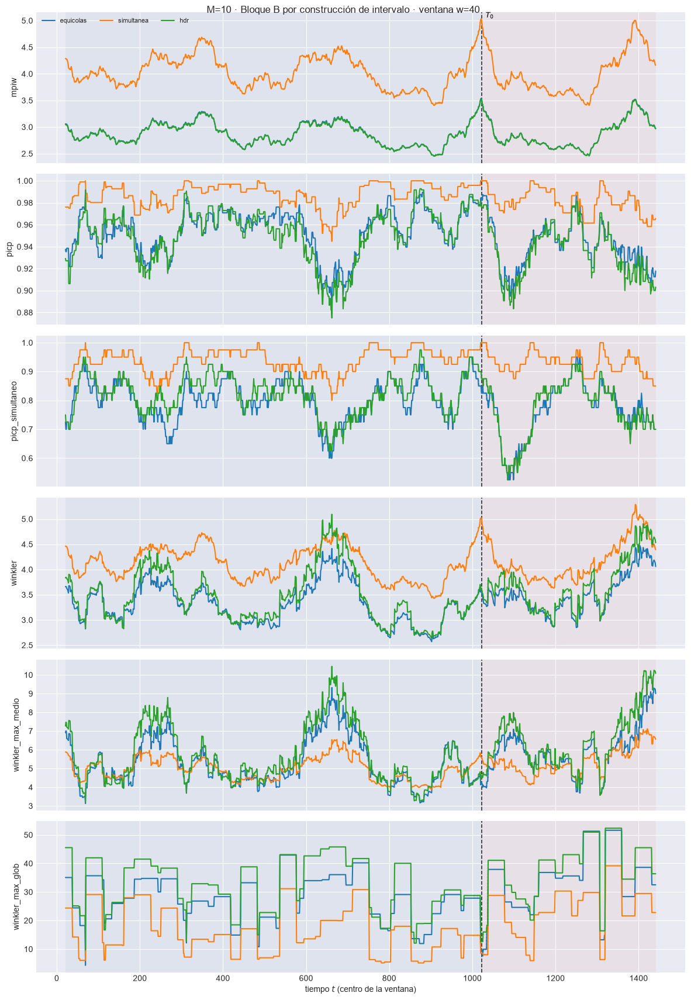

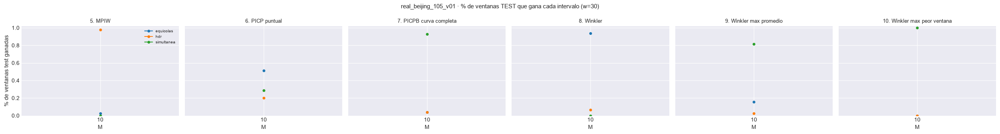

M,10
intervalo,
equicolas,2.4%
simultanea,0.0%
hdr,97.6%


M,10
intervalo,
equicolas,51.5%
simultanea,28.5%
hdr,20.0%


M,10
intervalo,
equicolas,3.7%
simultanea,92.7%
hdr,3.7%


M,10
intervalo,
equicolas,93.7%
simultanea,0.0%
hdr,6.3%


M,10
intervalo,
equicolas,15.6%
simultanea,81.7%
hdr,2.7%


M,10
intervalo,
equicolas,0.0%
simultanea,100.0%
hdr,0.0%


In [14]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        ti = filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza")
        ti.attrs["w"] = w
        plot_ventana_movil(
            ti, T0, METRICAS_B_COLS, columna_grupo="intervalo",
            title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · % de ventanas TEST que gana cada intervalo (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada intervalo (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1400 [test] cob=0.917 rmse=0.884


  2/10 (20.0%) t=0.0s eta=0.0s  t=1401 [test] cob=1.000 rmse=0.4963


  3/10 (30.0%) t=0.0s eta=0.0s  t=1402 [test] cob=1.000 rmse=0.8926


  4/10 (40.0%) t=0.0s eta=0.0s  t=1403 [test] cob=1.000 rmse=1.038


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1406 [test] cob=1.000 rmse=0.6079


  8/10 (80.0%) t=0.0s eta=0.0s  t=1407 [test] cob=1.000 rmse=0.526


  9/10 (90.0%) t=0.0s eta=0.0s  t=1408 [test] cob=1.000 rmse=0.7672


  10/10 (100.0%) t=0.0s eta=0.0s  t=1409 [test] cob=1.000 rmse=0.3214


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.992 (nominal 0.95)


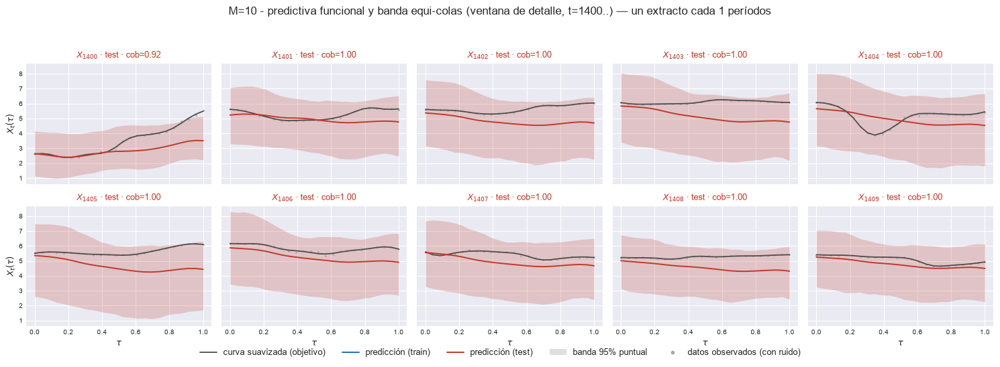

In [15]:
# Los N_DETALLE orígenes de la ventana de detalle (§3.2).
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[IDX_DET], e["X_pred"][IDX_DET], e["li_f"][IDX_DET], e["ls_f"][IDX_DET],
        grilla, T0, t=T_DET, cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[IDX_DET],
        title=f"M={M} - predictiva funcional y banda equi-colas (ventana de detalle, t={T0_DET}..)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1019 [train] cob=1.000 rmse=0.9119


  2/7 (28.6%) t=0.0s eta=0.0s  t=1020 [train] cob=0.958 rmse=1.025


  3/7 (42.9%) t=0.0s eta=0.0s  t=1021 [train] cob=1.000 rmse=0.7316


  4/7 (57.1%) t=0.0s eta=0.0s  t=1022 [train] cob=0.833 rmse=0.9921


  5/7 (71.4%) t=0.0s eta=0.0s  t=1023 [test] cob=1.000 rmse=0.8291


  6/7 (85.7%) t=0.0s eta=0.0s  t=1024 [test] cob=1.000 rmse=0.4907


  7/7 (100.0%) t=0.0s eta=0.0s  t=1025 [test] cob=1.000 rmse=0.7985


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.948 test=1.000 (nominal 0.95)


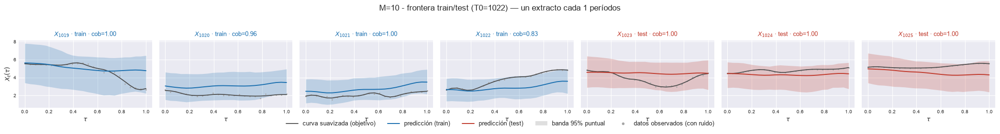

In [16]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1376, 1405]  rmse_f=1.020912


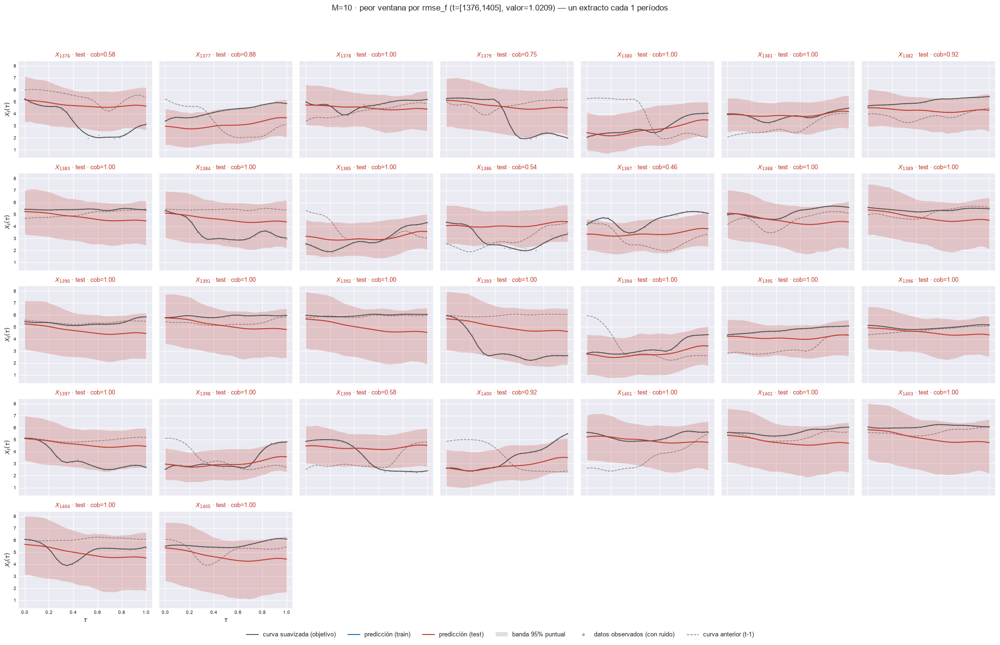

    t=[1368, 1397]  rmse_f=1.009763


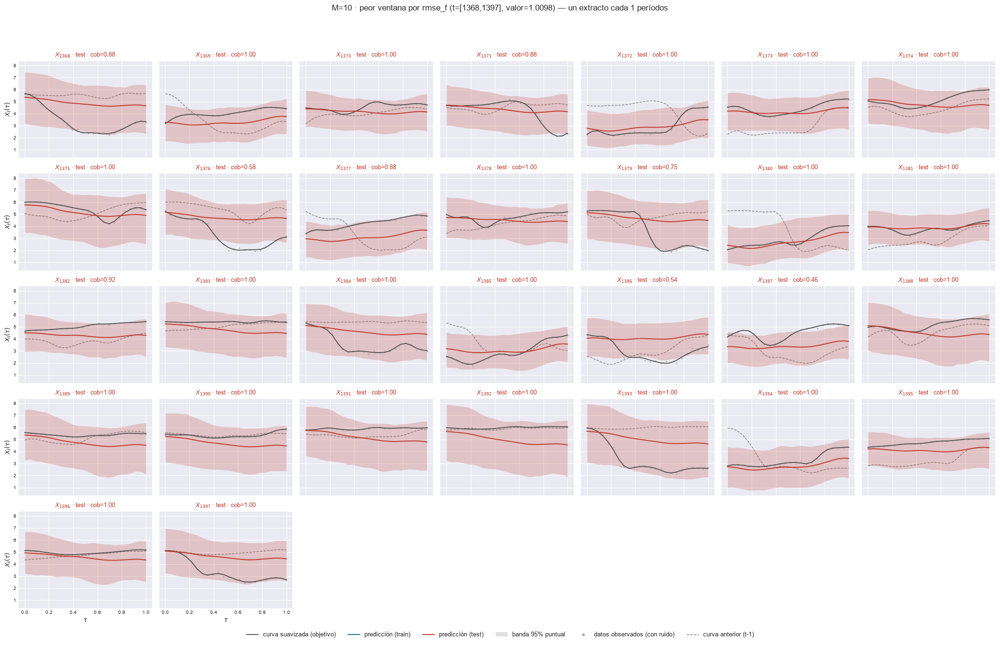

    t=[1374, 1403]  rmse_f=1.004278


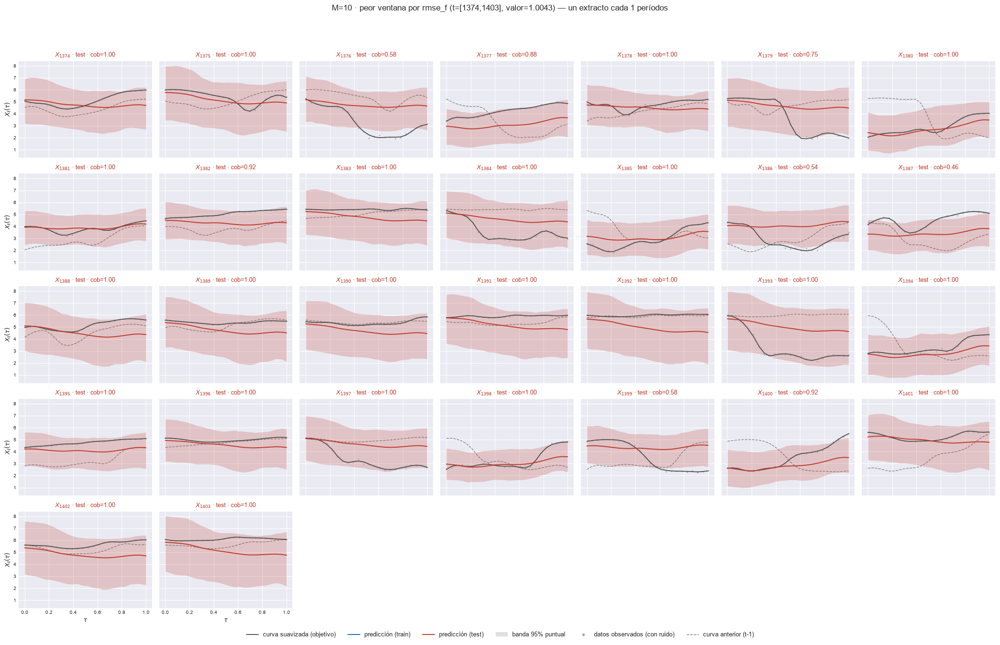

    t=[1375, 1404]  rmse_f=1.003738


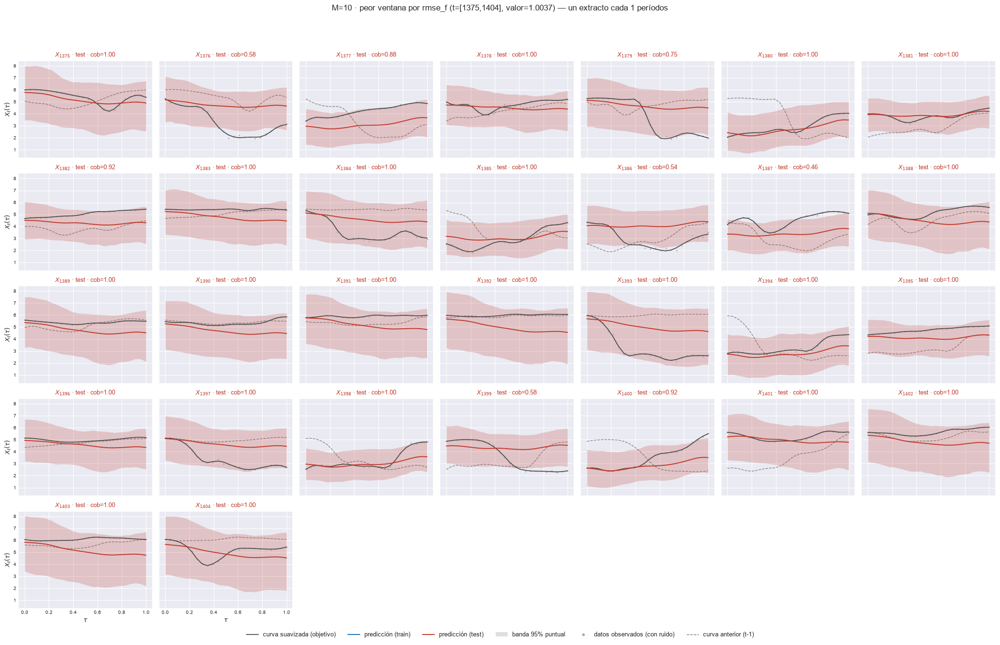

    t=[1383, 1412]  rmse_f=0.996046


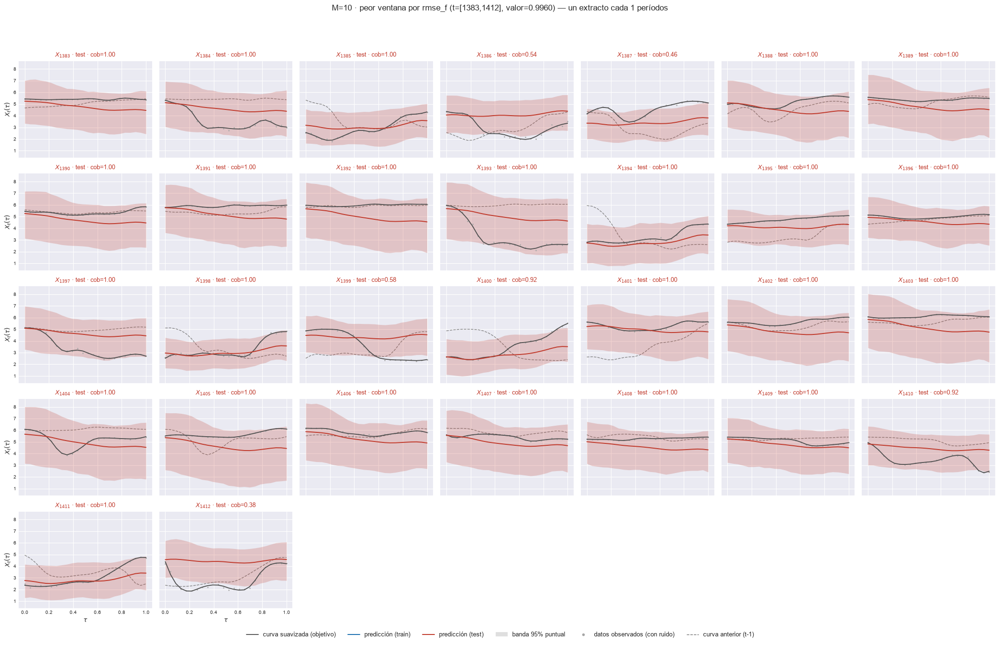

In [17]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

PIP global por covariable: el rezago 1 de cada score, propio y cruzados. Sin soporte verdadero contra el cual contrastar y, con una cadena, sin dispersión entre cadenas. La lectura que importa en la 105 es qué scores rezagados gobiernan cada componente y si el gating usa el nivel de ayer ($\xi_1$) para separar "sigue el episodio" de "se limpió".


In [18]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 10 variables, PIP en [0.578, 1.000]


  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 1 cadenas, 10 variables, PIP en [0.132, 1.000]


  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 1 cadenas, 10 variables, PIP en [0.110, 1.000]


  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 1 cadenas, 10 variables, PIP en [0.080, 1.000]


...

  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 1 cadenas, 10 variables, PIP en [0.111, 0.693]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 1 cadenas, 10 variables, PIP en [0.136, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20


[M=10] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.130,0.000,0.149,0.000,1.000,0.000,1.000,0.000,0.693,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.120,0.000,0.098,0.000,0.167,0.000,0.122,0.000,0.088,0.000,0.150,0.000,0.136,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.839,0.000,0.124,0.000,0.528,0.000,0.154,0.000,0.136,0.000,0.163,0.000,0.377,0.000
fpc_4_lag1,1.000,0.000,0.138,0.000,0.168,0.000,0.098,0.000,0.108,0.000,0.117,0.000,0.151,0.000,0.079,0.000,0.141,0.000,0.178,0.000
fpc_5_lag1,1.000,0.000,0.132,0.000,0.168,0.000,0.104,0.000,0.107,0.000,0.147,0.000,0.177,0.000,0.077,0.000,0.154,0.000,0.160,0.000
fpc_6_lag1,1.000,0.000,1.000,0.000,0.110,0.000,0.095,0.000,0.085,0.000,0.109,0.000,0.131,0.000,0.097,0.000,0.184,0.000,0.148,0.000
fpc_7_lag1,0.960,0.000,0.169,0.000,0.180,0.000,0.099,0.000,0.078,0.000,0.121,0.000,0.113,0.000,0.101,0.000,0.137,0.000,0.145,0.000
fpc_8_lag1,0.970,0.000,0.190,0.000,0.140,0.000,0.088,0.000,0.064,0.000,0.104,0.000,0.129,0.000,0.061,0.000,0.338,0.000,0.166,0.000
fpc_9_lag1,0.913,0.000,0.875,0.000,0.170,0.000,0.080,0.000,0.121,0.000,0.092,0.000,0.143,0.000,0.085,0.000,0.111,0.000,0.151,0.000


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [19]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=10] curva_suavizada      PICP puntual test = 0.9388 (nominal 0.95)  ·  PICP simultaneo test = 0.7629
[M=10] representacion_fpca  PICP puntual test = 0.9388 (nominal 0.95)  ·  PICP simultaneo test = 0.7629


M,10
metrica,
1. MAE (L^1),0.566393
10. Winkler max peor ventana,32.429386
2. RMSE (L^2),0.744512
3. E_max promedio por curva,1.067691
4. E_max peor de la ventana,2.413883
5. MPIW,2.851946
6. PICP puntual,0.938804
7. PICPB curva completa,0.762927
8. Winkler,3.522192


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,10
predictor,
esperanza,0.5664
mediana,0.5515
medoide,0.5603
modal,0.5786


M,10
predictor,
esperanza,0.7445
mediana,0.7503
medoide,0.7586
modal,0.8385


M,10
predictor,
esperanza,1.0677
mediana,1.0639
medoide,1.1033
modal,1.1031


M,10
predictor,
esperanza,2.4139
mediana,2.5453
medoide,2.6036
modal,2.9322


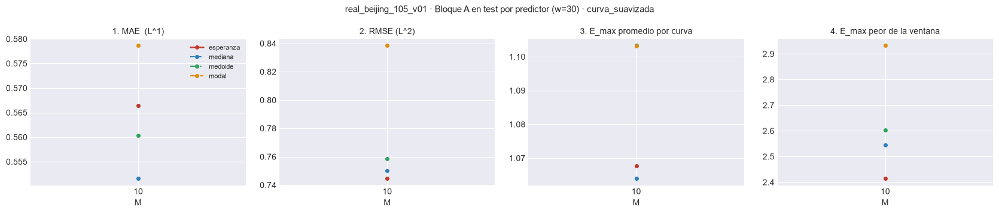

M,10
predictor,
esperanza,0.5664
mediana,0.5515
medoide,0.5603
modal,0.5786


M,10
predictor,
esperanza,0.7445
mediana,0.7503
medoide,0.7586
modal,0.8385


M,10
predictor,
esperanza,1.0677
mediana,1.0639
medoide,1.1033
modal,1.1031


M,10
predictor,
esperanza,2.4139
mediana,2.5453
medoide,2.6036
modal,2.9322


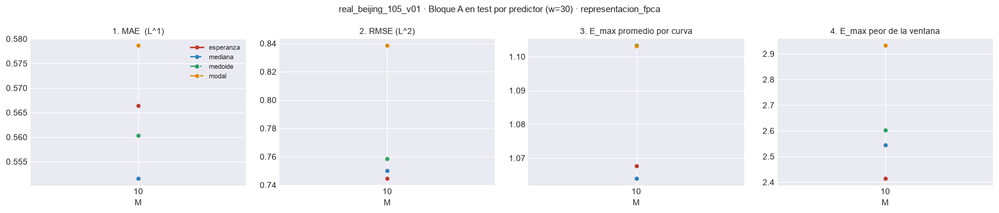

In [20]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,10
intervalo,
equicolas,2.8519
simultanea,3.9857
hdr,2.8468


M,10
intervalo,
equicolas,0.9388
simultanea,0.9803
hdr,0.9330


M,10
intervalo,
equicolas,0.7629
simultanea,0.9261
hdr,0.7635


M,10
intervalo,
equicolas,3.5222
simultanea,4.1693
hdr,3.7171


M,10
intervalo,
equicolas,6.0309
simultanea,5.3730
hdr,6.5724


M,10
intervalo,
equicolas,32.4294
simultanea,22.0211
hdr,36.1123


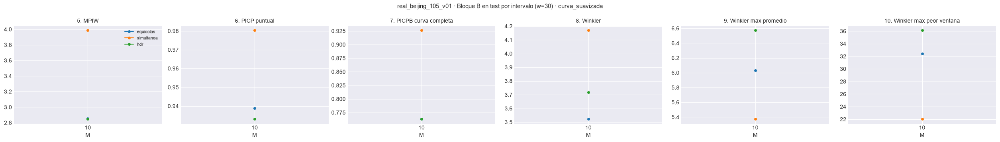

M,10
intervalo,
equicolas,2.8519
simultanea,3.9857
hdr,2.8468


M,10
intervalo,
equicolas,0.9388
simultanea,0.9803
hdr,0.9330


M,10
intervalo,
equicolas,0.7629
simultanea,0.9261
hdr,0.7635


M,10
intervalo,
equicolas,3.5222
simultanea,4.1693
hdr,3.7171


M,10
intervalo,
equicolas,6.0309
simultanea,5.3730
hdr,6.5724


M,10
intervalo,
equicolas,32.4294
simultanea,22.0211
hdr,36.1123


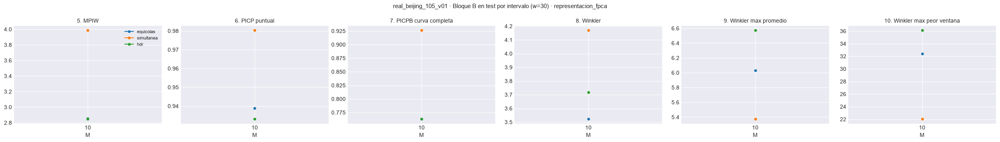

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.2s  t=16 [train] rmse=0.7072


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.5957


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.5296


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.7077


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.03252


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.02468


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.03813


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.0242


[ventana_movil_scores[FPC 10, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


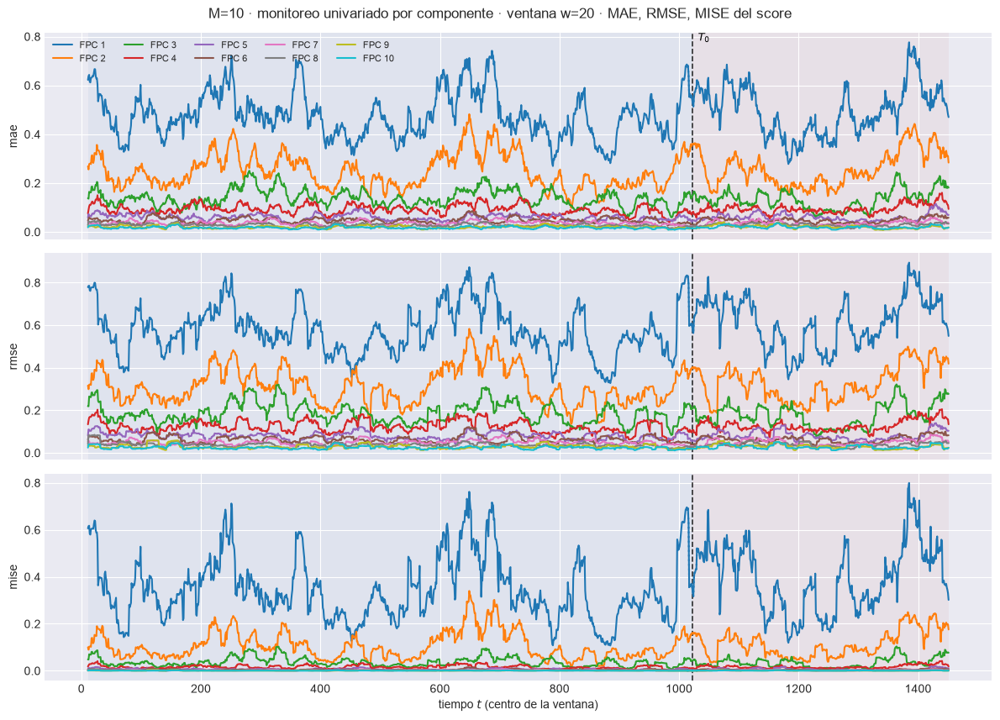

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.05214  w=30 test=0.05138


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.07122  w=30 test=0.07059


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.005073  w=30 test=0.004983


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_m10\91_ventana_univariado_w30.png


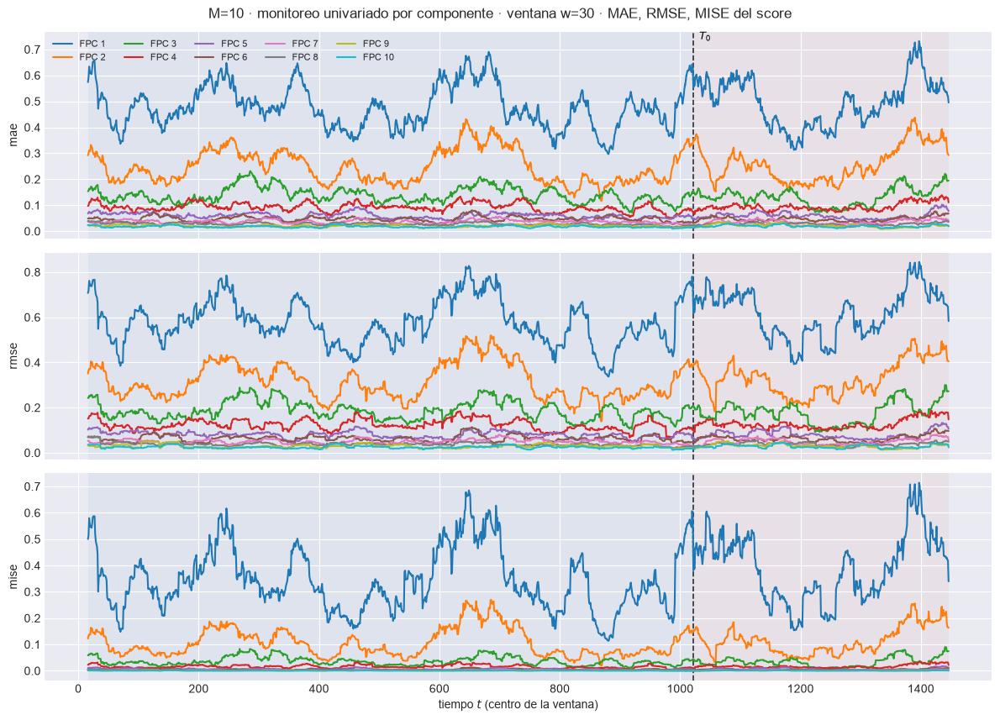

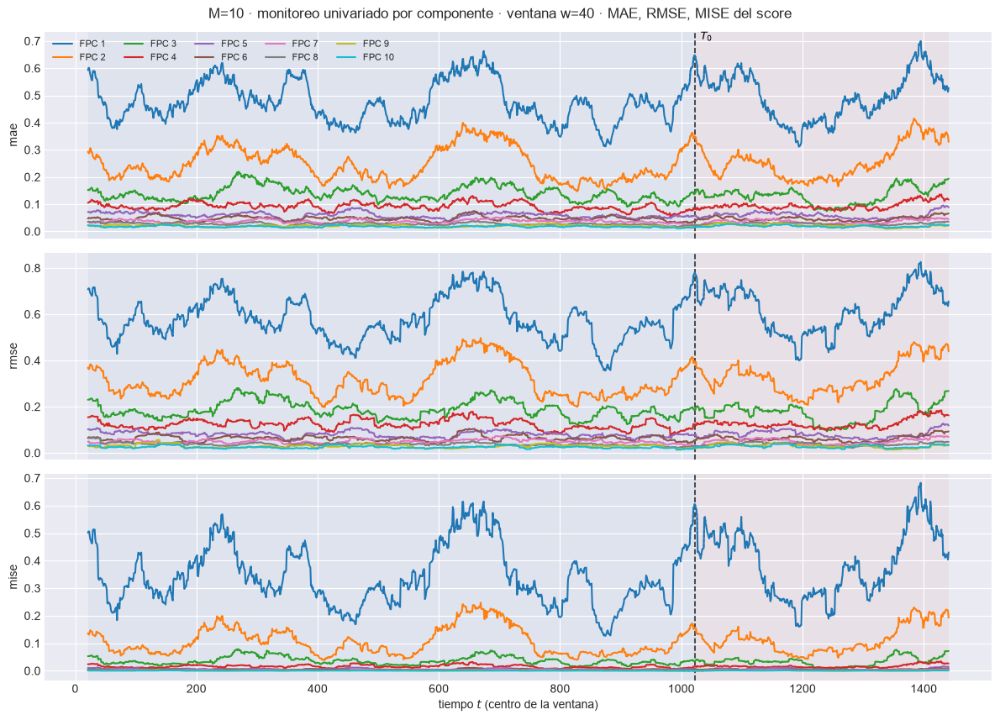

In [22]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

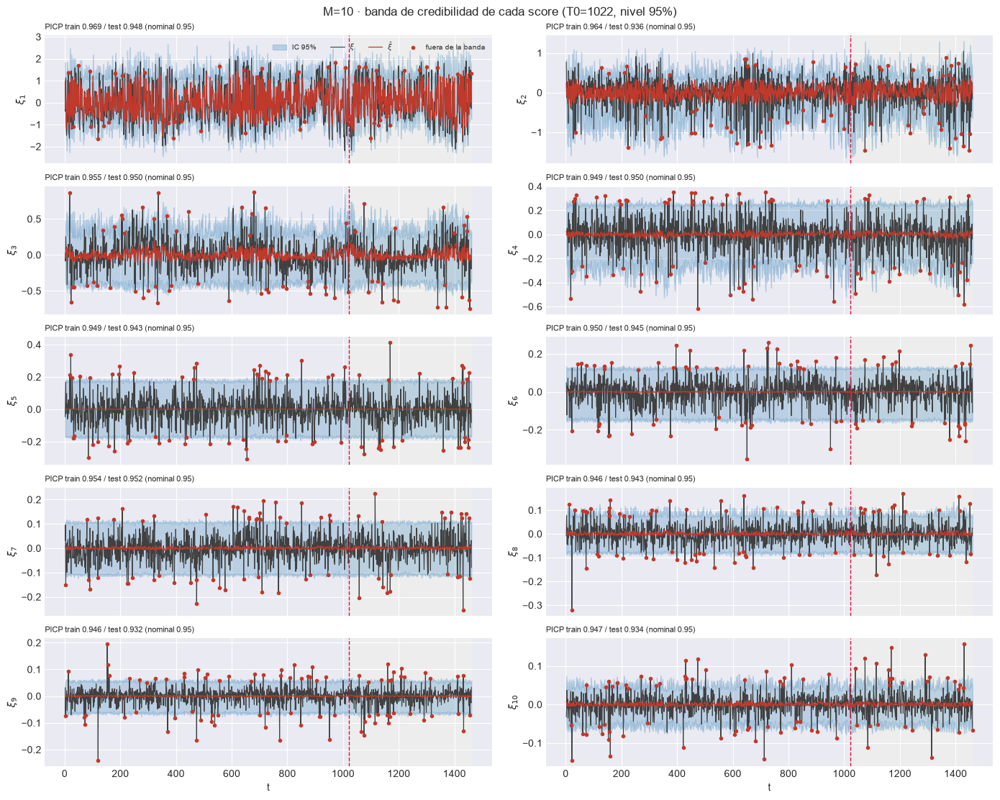

In [23]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


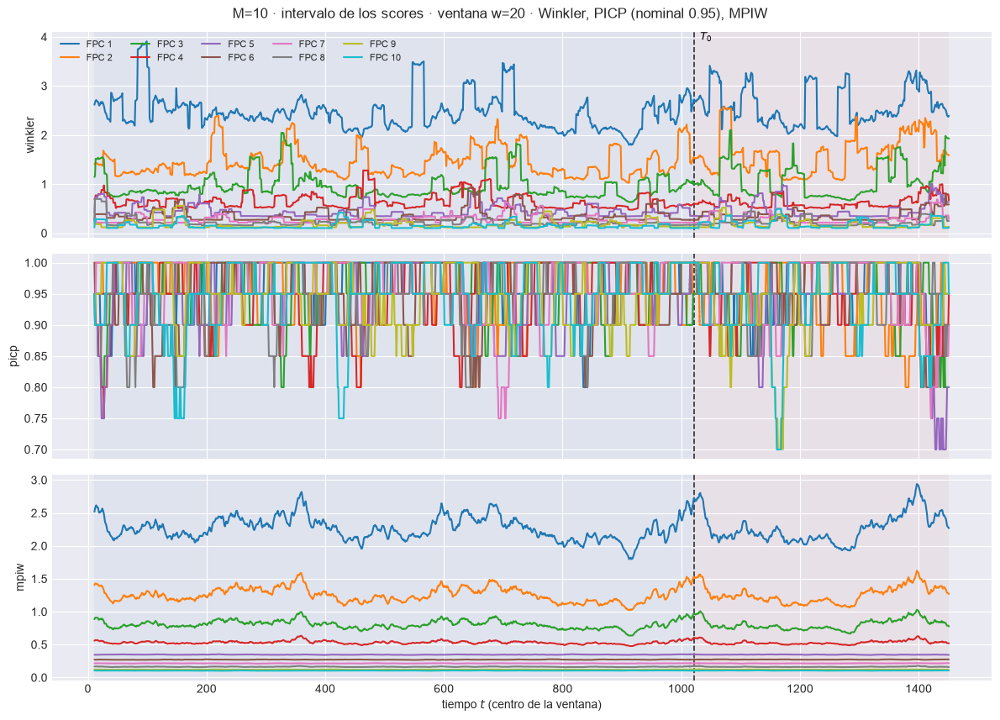

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.3966  w=30 test=0.3934


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9333


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.3098  w=30 test=0.3097


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_m10\93_ventana_scores_intervalo_w30.png


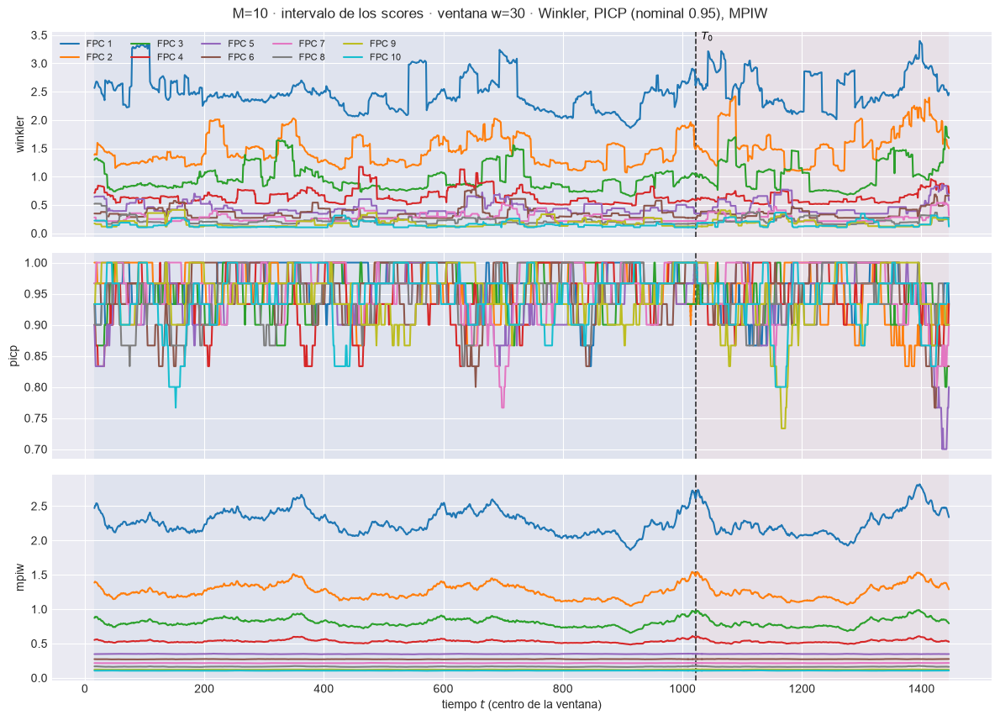

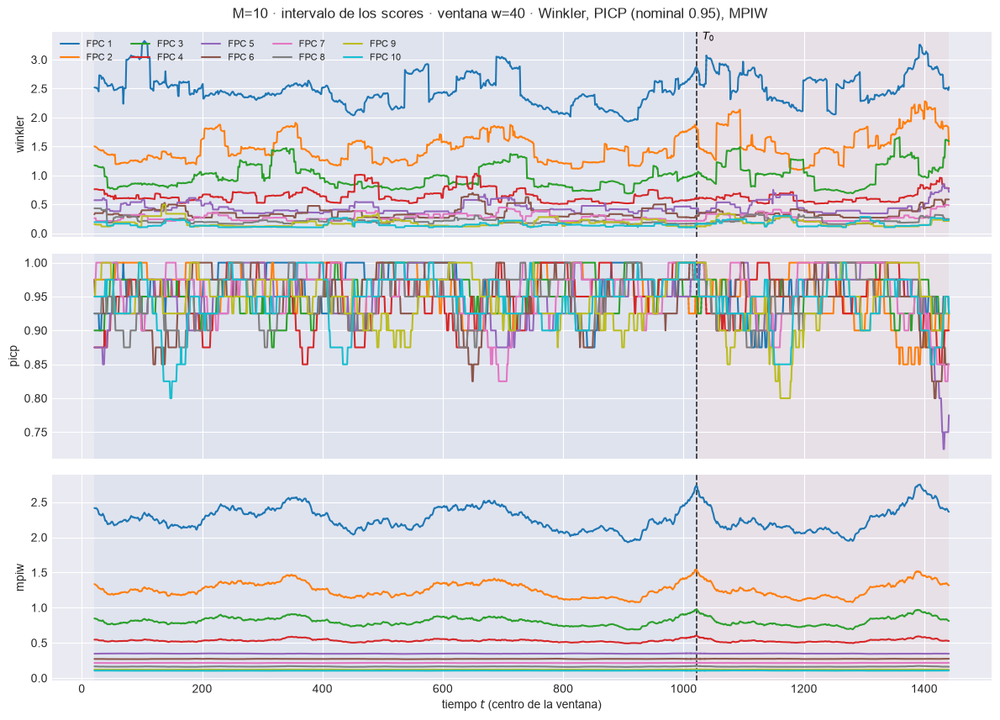

In [24]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

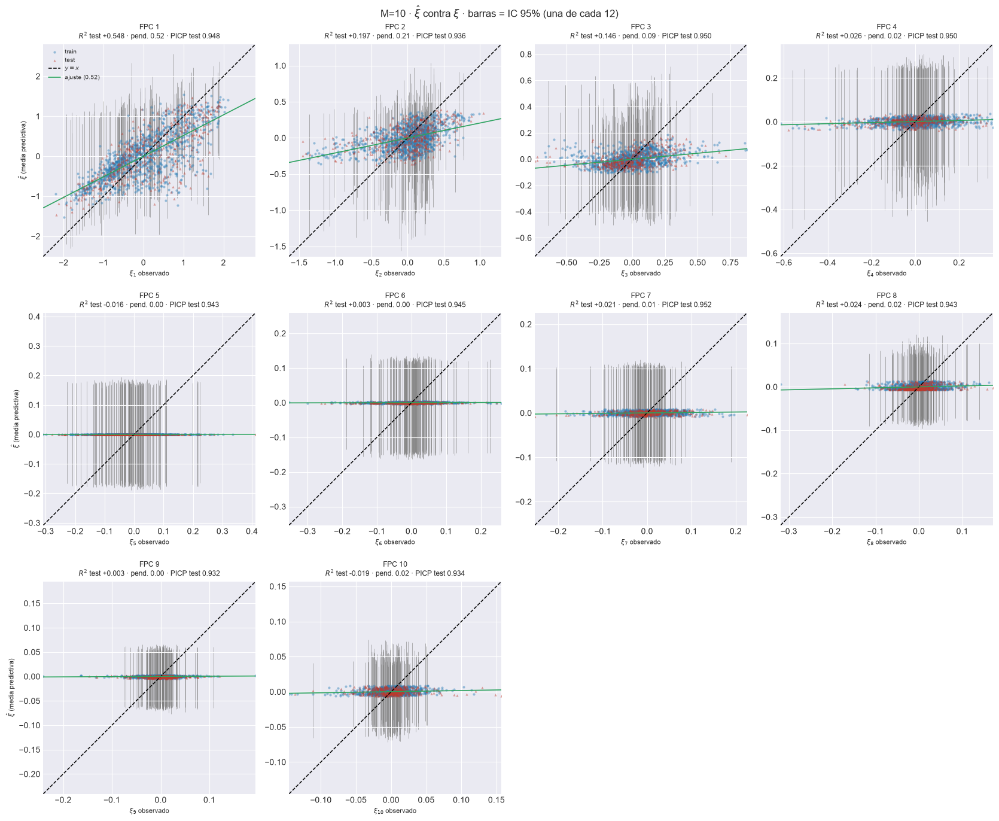

In [25]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas.

In [26]:
# Sobre los N_DETALLE orígenes de la ventana de detalle: cuentas k de N_DETALLE, descriptivas.
wn, MULTI = pesos_normalizados(grilla, PESOS_TAU), {}
for M in M_OK:
    e = EST[M]
    q16, q50, q84 = np.quantile(e["SC_draws"][:, IDX_DET], [0.16, 0.5, 0.84], axis=0)
    sep = np.abs(e["Y_hat"][IDX_DET] - q50) / np.maximum((q84 - q16) / 2.0, 1e-12)   # (N_DETALLE, M)
    por_score = pd.DataFrame({"componente": [f"FPC {c + 1}" for c in e["component_idx"]],
                              "n_origenes": N_DETALLE,
                              f"n_sep_gt_{UMBRAL_SEP}": (sep > UMBRAL_SEP).sum(axis=0),
                              "sep_mediana": np.median(sep, axis=0), "sep_max": sep.max(axis=0)})
    d = distancia_a_muestra_mas_cercana(curvas_draws(e, DIS, IDX_DET), e["X_PRED"]["mediana"][IDX_DET],
                                        grilla, PESOS_TAU, N_REF_NN, SEED_PRED)
    por_origen = pd.DataFrame({"t": T_DET, **d, "l1_esperanza_mediana":
                               np.abs(e["X_pred"][IDX_DET] - e["X_PRED"]["mediana"][IDX_DET]) @ wn,
                               "sep_max_score": sep.max(axis=1)})
    por_score.to_csv(e["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    por_origen.to_csv(e["paths"]["out_report"] / "61_distancia_mediana_muestra.csv", index=False)
    MULTI[M] = (por_score, por_origen)
multi_bar = pd.concat([MULTI[M][0].assign(M=M, t0_detalle=T0_DET) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)

display(multi_bar.pivot(index="componente", columns="M", values=f"n_sep_gt_{UMBRAL_SEP}")
        .reindex([f"FPC {k}" for k in range(1, max(M_OK) + 1)])
        .style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=N_DETALLE, axis=None)
        .set_caption(f"Ventana de detalle (t={T0_DET}..): orígenes, de {N_DETALLE}, con "
                     f"|esperanza − mediana| > {UMBRAL_SEP} sd robusta, por score (descriptivo)"))
display(pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK}).style.format("{:.2f}")
        .set_caption("Ventana de detalle · razón d(mediana, extracción más cercana) / d típica, por origen"))

M,10
componente,
FPC 1,9
FPC 2,8
FPC 3,0
FPC 4,0
FPC 5,0
FPC 6,0
FPC 7,0
FPC 8,0
FPC 9,0


,10
t,
1400,0.54
1401,0.66
1402,0.63
1403,0.79
1404,0.93
1405,0.43
1406,0.46
1407,0.61
1408,0.42


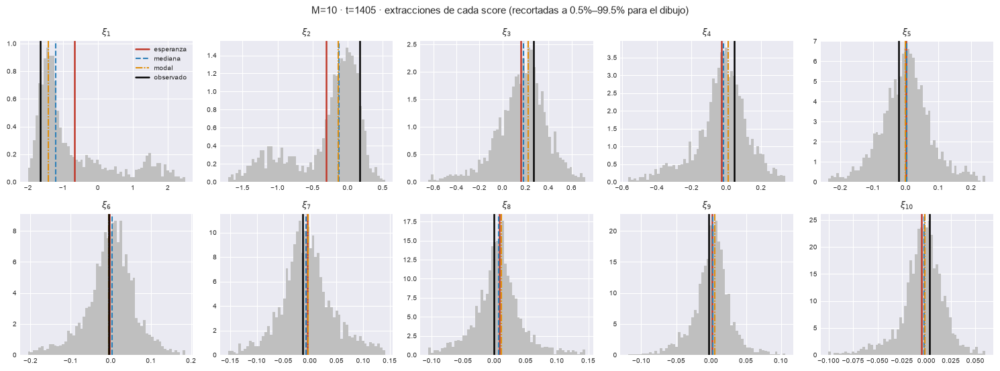

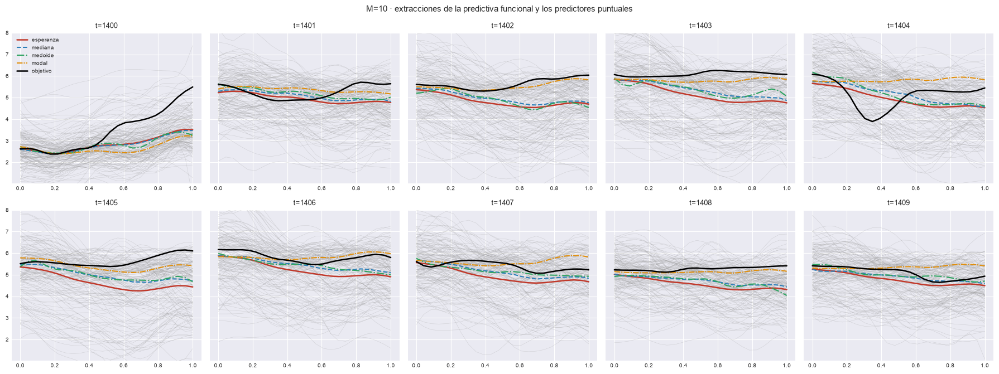

In [27]:
# El origen más multimodal de la ventana: extracciones por score; los N_DETALLE: curvas y predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    i_mm = int(IDX_DET[int(np.argmax(po["sep_max_score"].to_numpy()))])
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_mm, marcas, int(t_orig[i_mm]), M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{int(t_orig[i_mm])}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 y §12.4 sobre toda la serie; §12.2, §12.3, §12.5 y el cierre de §12.4 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/1460 origenes


    comportamientos: 500/1460 origenes


    comportamientos: 750/1460 origenes


    comportamientos: 1000/1460 origenes


    comportamientos: 1250/1460 origenes


M=10: K en test  K=1: 100.0%   (recorte no, 29 s)


M,10
K,
1,99.8%
2,0.2%
3,0.0%
4,0.0%
5,0.0%
6,0.0%


M,10
K,
1,100.0%
2,0.0%
3,0.0%
4,0.0%
5,0.0%
6,0.0%


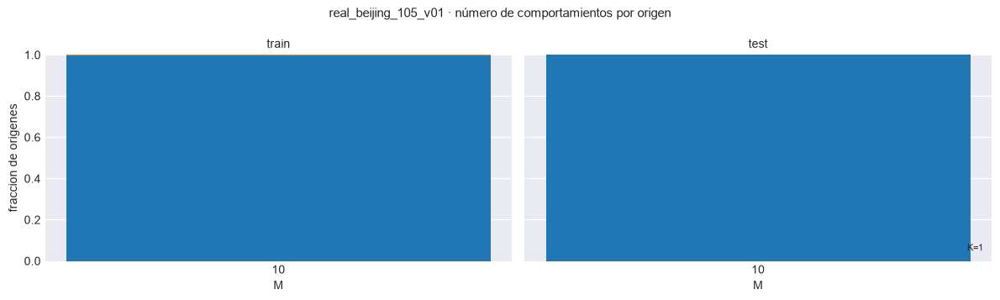

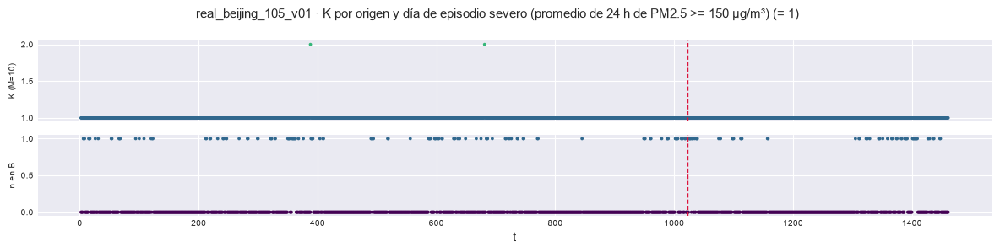

In [28]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0, n_B=EVENTO_OR,
             titulo=f"{EXPERIMENT_BASE} · K por origen y {DESCR_EVENTO} (= 1)",
             save_path=PATH_BARRIDO / "102b_K_serie.png")
plt.show()


### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

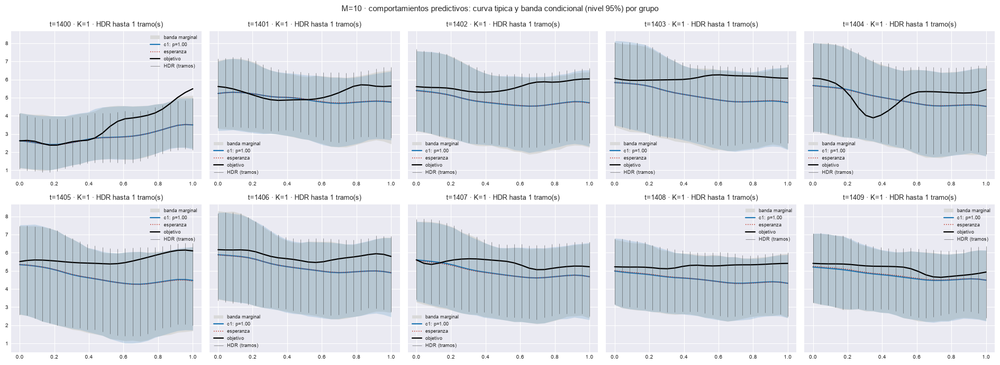

In [29]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M=10: catalogo global con L=2 comportamiento(s), masas [0.9, 0.1]


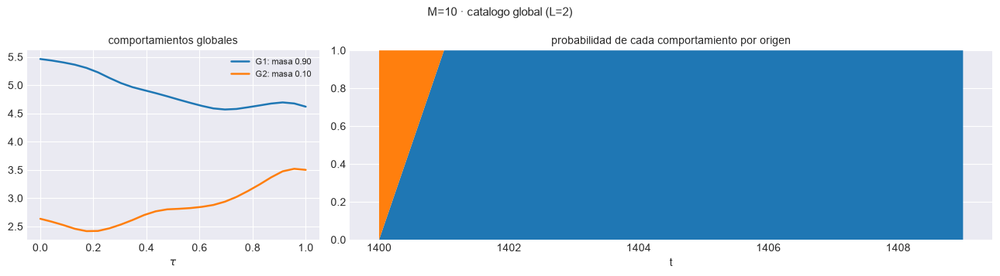

In [30]:
# catalogo_barrido sólo usa es_train para la máscara: la ventana de detalle hace de 'test'.
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 Comportamientos contra el calendario y los días de episodio

No hay régimen verdadero. La referencia externa son los **episodios severos** (el día predicho supera `UMBRAL_SEVERO_PM25` µg/m³ de promedio) y el calendario (día de la semana y mes: los episodios son de la temporada de calefacción, noviembre-marzo). Sobre toda la serie de prueba, la tabla cruzada de $K$ con el día de la semana, el mes y el episodio del día predicho y del anterior (`65_*` por $M$, `104_*` en el barrido). Hipótesis: $K \ge 2$ aparece el día siguiente a un episodio, cuando mañana puede seguir contaminado o limpiarse con el viento del norte. Al final, la ventana de detalle como cuentas.


In [31]:
DIAS_ORDEN = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
AYER = f"ayer_{NOMBRE_EVENTO}"
filas = []
for M in M_OK:
    K = EST[M]["COMP"]["K"].astype(int)
    df = pd.DataFrame({"M": M, "t": t_orig, "bloque": np.where(es_train, "train", "test"), "K": K,
                       **{k: v for k, v in VERDAD_DET.items()}})
    df[NOMBRE_EVENTO], df[AYER] = df[NOMBRE_EVENTO].astype(bool), df[AYER].astype(bool)
    df.drop(columns="M").to_csv(EST[M]["paths"]["out_report"] / "65_comportamientos_calendario.csv", index=False)
    filas.append(df)
    te = df[df.bloque == "test"]
    cruz = pd.crosstab(te["dia_semana"], te["K"]).reindex(DIAS_ORDEN).fillna(0).astype(int)
    display(cruz.style.set_caption(f"M={M} · TEST · orígenes por día de la semana del día predicho y K (cuentas)"))
    display(pd.crosstab(te["mes"], te["K"]).style.set_caption(f"M={M} · TEST · orígenes por mes del día predicho y K (cuentas)"))
    display(pd.crosstab([te[NOMBRE_EVENTO], te[AYER]], te["K"])
            .style.set_caption(f"M={M} · TEST · orígenes por {NOMBRE_EVENTO} del día predicho y del anterior, y K (cuentas)"))
    k2 = te[te.K >= 2]
    print(f"M={M}: K >= 2 en {len(k2)} de {len(te)} orígenes de test · de ellos, día predicho {NOMBRE_EVENTO} "
          f"{int(k2[NOMBRE_EVENTO].sum())} y día anterior {NOMBRE_EVENTO} {int(k2[AYER].sum())} · "
          f"base en test: {te[NOMBRE_EVENTO].mean():.0%} de los días predichos son {NOMBRE_EVENTO}")
CAL = pd.concat(filas, ignore_index=True)
CAL.to_csv(PATH_BARRIDO / "104_comportamientos_calendario_por_M.csv", index=False)
display(CAL[CAL.t.isin(T_DET)].set_index(["M", "t"])[["fecha", "dia_semana", "mes", NOMBRE_MEDIDA, NOMBRE_EVENTO, AYER, "K"]]
        .style.format({NOMBRE_MEDIDA: "{:.3f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..{T0_DET + N_DETALLE - 1}): calendario, {NOMBRE_EVENTO} y K por origen (descriptivo)"))


K,1
dia_semana,
Mon,63
Tue,63
Wed,62
Thu,62
Fri,63
Sat,63
Sun,63


K,1
mes,
1,62
2,57
3,31
4,30
5,31
6,30
7,31
8,31
9,30


M=10: K >= 2 en 0 de 439 orígenes de test · de ellos, día predicho episodio 0 y día anterior episodio 0 · base en test: 13% de los días predichos son episodio


### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, calendario (fecha, día de la semana, mes), episodio del día predicho y del anterior, y error de cada predictor.

In [32]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
cols_p = sorted([c for c in DETALLE.columns if c.startswith("p_")], key=lambda c: int(c[2:]))
DETALLE = DETALLE[["M", "t", "K"] + cols_p + [c for c in DETALLE.columns if c not in ["M", "t", "K"] + cols_p]]
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,pm25_media,episodio,ayer_episodio
t,,,,,,,,,,,,,,,,,,,,,,,
1400,1,1.000,1,2.845,0.917,3.708,1.000,2.785,0.875,0.606,0.854,0.627,0.879,0.657,0.924,0.817,1.099,2016-12-29,Thu,12,52.674,0,0
1401,1,1.000,1,3.716,1.000,5.245,1.000,3.652,1.000,0.368,0.487,0.361,0.440,0.373,0.440,0.355,0.394,2016-12-30,Fri,12,201.537,1,0
1402,1,1.000,1,4.196,1.000,6.000,1.000,4.153,1.000,0.795,0.890,0.654,0.776,0.705,0.857,0.109,0.140,2016-12-31,Sat,12,286.049,1,1
1403,1,1.000,1,4.420,1.000,6.542,1.000,4.403,1.000,0.933,1.042,0.728,0.831,0.712,0.801,0.288,0.316,2017-01-01,Sun,1,441.885,1,1
1404,1,1.000,1,4.668,1.000,6.671,1.000,4.682,1.000,0.617,0.682,0.614,0.726,0.622,0.736,0.770,0.920,2017-01-02,Mon,1,196.539,1,1
1405,1,1.000,1,4.841,1.000,7.414,1.000,4.807,1.000,0.981,1.092,0.649,0.783,0.628,0.752,0.312,0.387,2017-01-03,Tue,1,290.637,1,1
1406,1,1.000,1,4.255,1.000,6.322,1.000,4.273,1.000,0.564,0.605,0.352,0.406,0.374,0.449,0.197,0.222,2017-01-04,Wed,1,344.705,1,1
1407,1,1.000,1,4.202,1.000,6.244,1.000,4.175,1.000,0.482,0.531,0.311,0.333,0.263,0.298,0.301,0.370,2017-01-05,Thu,1,224.390,1,1
1408,1,1.000,1,3.455,1.000,4.928,1.000,3.451,1.000,0.707,0.766,0.550,0.600,0.568,0.646,0.142,0.154,2017-01-06,Fri,1,194.479,1,1
